<a href="https://colab.research.google.com/github/Ethan-Tse/econ3916-midterm/blob/main/Econ_3916_Midterm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 Midterm Project — Econometric Foundation

**ECON 3916 · Applied Data Analytics** · Topics 1-14 · 100 points · your role: Independent analyst

This is the **starter**: the structure of the project in rubric order. Fill the empty cells and keep every heading so the grader finds each section. The brief on Canvas has the full text of every section and the rubric. The grader reruns this notebook from the top, so every number, table and figure in your report must come from a cell here.

**🛑 This project is entirely NO AI.** Not phases one to three — all of it. No AI for the code, the analysis, the writing, or the editing. This is the one assessment in the course that establishes you can do the work unaided, and it is the one you will draw on when an interviewer asks what you built. Everything you have practised with a co-pilot, you do here alone.

## Start here

Work top to bottom. What each part of this notebook is for:

1. **Data provenance**: where the file came from. It feeds Section 1 and your README.
2. **Section 1**: load the data into a DataFrame called `df`, then run the *Section 1 self-check* cell and answer the questions under it. Do this before the **Mon 2 Nov** checkpoint.
3. **Section 2**: figures, each with a caption that states a finding.
4. **Section 3**: the OLS model, with a draft committed by **Fri 6 Nov**.
5. **Section 4**: diagnostics, only after Topic 14.
6. **Section 5**: words only.
7. **Numbers my report quotes**: last. Every number in the report must be printed there.

The brief's *Six checks before you post* list the problems that came up most often in Checkpoint 1. Read them before you settle on your controls.

## Setup

Imports only. Add any others you need here, at the top.

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

## Data provenance

Fill these in when you download the data. They feed Section 1 and your README.

In [24]:
SOURCE_URL = "https://educationdata.urban.org/"       # Urban Institute Education Data Portal (EDFacts graduation rates; CCD finance and enrollment)
DOWNLOAD_DATE = "2026-11-05 (graduation rates; 2018-2020 finance), 2026-11-08 (2015-2017 finance)"    # YYYY-MM-DD
FILE_NAME = "GraduationRates.csv, Expenditures_Finances.csv, Finance_2015_2017.csv, cpi_annual.csv"        # as saved in the repository's data/ folder
CPI_SOURCE = "FRED series CPIAUCNS (BLS CPI-U, not seasonally adjusted); annual average of the monthly index, 2015-2018"

**Who collected it, for what purpose, what is missing and why?**

The Urban Institute's Education Data Portal republishes two federal sources: graduation rates that states report to the U.S. Department of Education through EDFacts, and spending and enrollment from the National Center for Education Statistics' Common Core of Data. The graduation rate is the share of a district's ninth graders who earn a regular diploma within four years; my file has it for 2018 only. Spending is current instructional expenditure per pupil, restated in 2018 dollars. Of 1,958 districts, 587 have no graduation rate, for different reasons: 525 are in California, and 437 of those have "Elementary" in their name and so likely have no high school and no graduates. In the smallest districts, privacy rules suppress or coarsen the rate (I report 105 districts at exactly 75%, a range midpoint). I treat the small-district gaps as MAR, since reporting depends on cohort size, which I observe and control for, and I cannot rule out an MNAR part. My results therefore describe districts with a high school and a reported rate, and the sample leans toward Texas and larger districts.

## Section 1: The Question and the Data (20 pts)

State the question in one sentence, and say why it matters and to whom. Describe the data as a product of measurement decisions, name the missingness mechanism (MCAR, MAR or MNAR) and defend the label. Build a summary-statistics table a reader can read without asking you a question.

In [25]:
# Load and clean data: 2018 graduating cohort; spending averaged over 2015-2018 (grades 9-12), in 2018 dollars
BASE = "https://raw.githubusercontent.com/Ethan-Tse/econ3916-midterm/main/Data/"
GRAD_FILE = BASE + "GraduationRates.csv"
FIN_FILE_2018 = BASE + "Expenditures_Finances.csv"        # 2018-2020 finance
FIN_FILE_EARLY = BASE + "Finance_2015_2017.csv"           # 2015-2017 finance
COHORT_YEAR = 2018
SPEND_YEARS = [2015, 2016, 2017, 2018]                    # the four years the 2018 cohort was in high school
target_agency = "Regular local school district"
EXCLUDE_COE = True       # drop County Offices of Education (special-purpose agencies)

# Prices: FRED's public CSV (no API key) and a deflate() function
def load_fred(series_id, start="2015-01-01", end="2018-12-01"):
    """Return one FRED series as a pandas Series indexed by date."""
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}&cosd={start}&coed={end}"
    frame = pd.read_csv(url)
    frame.columns = ["date", series_id]
    frame["date"] = pd.to_datetime(frame["date"])
    frame[series_id] = pd.to_numeric(frame[series_id], errors="coerce")
    return frame.set_index("date")[series_id].dropna()

def deflate(nominal, cpi_then, cpi_base=100):
    """Convert a nominal value into base-year dollars."""
    return nominal * cpi_base / cpi_then

try:                                                      # CPI-U, not seasonally adjusted; its annual average is the BLS annual CPI
    cpi_month = load_fred("CPIAUCNS")
    cpi_year = cpi_month.groupby(cpi_month.index.year).mean().round(3)
    cpi_year.rename("cpi").rename_axis("year").to_csv("cpi_annual.csv")      # keep the numbers used, to commit with the data
except Exception:                                         # FRED unreachable: read the saved copy of the same four numbers
    cpi_year = pd.read_csv(BASE + "cpi_annual.csv", index_col="year")["cpi"]

df_grads = pd.read_csv(GRAD_FILE, encoding="utf-8-sig")
fin = pd.concat([pd.read_csv(FIN_FILE_EARLY, encoding="utf-8-sig"),
                 pd.read_csv(FIN_FILE_2018, encoding="utf-8-sig")], ignore_index=True)
fin = fin[fin["year"].isin(SPEND_YEARS)].drop_duplicates(["leaid", "year"])

# Text such as "Not applicable" or "Missing/not reported" becomes NaN; zero enrollment is not a real value
fin["exp_current_instruction_total"] = pd.to_numeric(fin["exp_current_instruction_total"], errors="coerce")
fin["enrollment"] = pd.to_numeric(fin["enrollment"], errors="coerce").replace(0, np.nan)
df_grads["grad_rate_midpt"] = pd.to_numeric(df_grads["grad_rate_midpt"], errors="coerce")
df_grads["enrollment"] = pd.to_numeric(df_grads["enrollment"], errors="coerce").replace(0, np.nan)

# Traditional public school systems only
df_grads = df_grads[(df_grads["agency_type"] == target_agency) & (df_grads["year"] == COHORT_YEAR)].copy()
fin = fin[fin["agency_type"] == target_agency].copy()
if EXCLUDE_COE:
    df_grads = df_grads[~df_grads["lea_name"].str.contains("County Office of Education", case=False)]
    fin = fin[~fin["lea_name"].str.contains("County Office of Education", case=False)]

# Annual per-pupil instructional spending, in nominal and in 2018 dollars; then the average over all four years
fin["spending_nominal"] = fin["exp_current_instruction_total"] / fin["enrollment"]
fin["spending_real"] = deflate(fin["spending_nominal"], fin["year"].map(cpi_year), cpi_year[COHORT_YEAR])
wide_real = fin.pivot(index="leaid", columns="year", values="spending_real").reindex(columns=SPEND_YEARS)
wide_nom = fin.pivot(index="leaid", columns="year", values="spending_nominal").reindex(columns=SPEND_YEARS)
all_four = wide_real.notna().all(axis=1)                  # a district needs all four years to have an average
spend = pd.DataFrame({
    "spending_per_pupil": wide_real[COHORT_YEAR],                       # 2018 only
    "spending_4yr_avg": wide_real.mean(axis=1).where(all_four),         # 2018 dollars
    "spending_4yr_nominal": wide_nom.mean(axis=1).where(all_four),      # same average, not adjusted for prices
}).reset_index()

# One row per district: the 2018 graduation rate and that district's 4-year spending
df = df_grads.merge(spend, on="leaid", how="left", validate="one_to_one")

# Sample-flow counts for the report
n_regular = len(df)
n_with_grad = int(df["grad_rate_midpt"].notna().sum())
n_with_spend = int((df["grad_rate_midpt"].notna() & df["spending_4yr_avg"].notna()).sum())
est = df.dropna(subset=["grad_rate_midpt", "spending_4yr_avg", "enrollment"]).copy()

# Table 1: Summary Statistics (estimation sample, so every row has the same N)
summary_vars = {
    "grad_rate_midpt": "High School Graduation Rate, 2018 cohort (%)",
    "spending_4yr_avg": "4-Year Avg Instructional Spending per Pupil, 2015-2018 (2018 $)",
    "spending_4yr_nominal": "Same 4-Year Average, not adjusted for prices ($)",
    "spending_per_pupil": "2018 Instructional Spending per Pupil ($)",
    "enrollment": "District Total Enrollment, 2018",
}
summary_table = est[list(summary_vars.keys())].rename(columns=summary_vars).describe().T
summary_table = summary_table[["count", "mean", "std", "min", "50%", "max"]]
summary_table.columns = ["N", "Mean", "Std Dev", "Min", "Median", "Max"]
summary_table["N"] = summary_table["N"].astype(int)

print(f"Regular districts in {COHORT_YEAR}: {n_regular:,}   with a graduation rate: {n_with_grad:,}   "
      f"also with 4-year spending: {n_with_spend:,}   estimation sample: {len(est):,}")
print(f"CPI-U annual averages used (1982-84 = 100): {cpi_year.to_dict()}")
print("\nTable 1: Summary Statistics for California and Texas School Districts (estimation sample)")
display(summary_table.round(2))

Regular districts in 2018: 1,958   with a graduation rate: 1,371   also with 4-year spending: 1,366   estimation sample: 1,366
CPI-U annual averages used (1982-84 = 100): {2015: 237.017, 2016: 240.007, 2017: 245.12, 2018: 251.107}

Table 1: Summary Statistics for California and Texas School Districts (estimation sample)


,N,Mean,Std Dev,Min,Median,Max
"High School Graduation Rate, 2018 cohort (%)",1366,90.71,7.51,5.00,92.00,99.00
"4-Year Avg Instructional Spending per Pupil, 2015-2018 (2018 $)",1366,6819.74,1600.51,3037.93,6541.08,32352.72
"Same 4-Year Average, not adjusted for prices ($)",1366,6610.90,1555.34,2989.99,6343.50,31654.14
2018 Instructional Spending per Pupil ($),1366,7063.91,2216.20,4619.15,6673.08,61840.43
"District Total Enrollment, 2018",1366,6999.75,19191.31,61.00,1675.00,495255.00


In [26]:
# Section 1 self-check: run once your data is loaded into a DataFrame called df.
# It prints what Section 1 has to report. It doesn't judge your choices: answer the questions below.
UNIT = "district"        # one row is one what? e.g. "county" or "country-year"
OUTCOME = "grad_rate_midpt"     # your dependent variable's column name
MAIN_X = "spending_4yr_avg"      # your main explanatory variable's column name
CONTROLS = ["enrollment", "state_location"]    # every other column in your model

if "df" in globals():
    print(f"Rows: {len(df):,}   Columns: {df.shape[1]}   One row is: {UNIT or '(fill in UNIT)'}")
    cols = [c for c in [OUTCOME, MAIN_X, *CONTROLS] if c]
    absent = [c for c in cols if c not in df.columns]
    if absent:
        print("Not in df:", absent)
    present = [c for c in cols if c in df.columns]
    if present:
        print("\nMissing values per column:")
        print(df[present].isna().sum().to_string())
    if OUTCOME in df.columns and pd.api.types.is_numeric_dtype(df[OUTCOME]):
        print(f"\nSkew of {OUTCOME}: {df[OUTCOME].skew():.2f} (above about 1, consider a log)")
else:
    print("Load your data into a DataFrame called df first, then run this cell.")

Rows: 1,958   Columns: 12   One row is: district

Missing values per column:
grad_rate_midpt     587
spending_4yr_avg     11
enrollment            7
state_location        0

Skew of grad_rate_midpt: -3.51 (above about 1, consider a log)


**Answer before you go on.**

**1. For each control: does your main explanatory variable change it? If yes, it is on the path from X to Y. Drop it, or run with and without and say what each version measures.**
No. The state is fixed and a district’s spending cannot move it from California to Texas. District enrollment is largely predetermined, since a district’s size in 2018 reflects its population and history more than its spending over the previous four years, so I treat it as a confounder rather than a mediator. The one risk is that spending could slowly draw families into a district and raise enrollment, so I will check how much the coefficient on spending changes with and without enrollment and report what each version measures.

**2. Are all your variables in the same units and for the same years?**
Yes. Every variable describes the 2018 graduating cohort, with spending averaged over 2015 to 2018, the four years that cohort was in grades 9 to 12. One row is one district. Graduation rates are percentages and spending is instructional dollars per pupil. Spending is in nominal dollars, not adjusted for inflation across 2015 to 2018

**3. If your question is about a policy, where is the period before it?**
It is not a policy question. The question concerns continuous variation in spending across districts, not a before-and-after change, so there is no policy date and no pre-period. I use one cross-section and do not estimate a difference-in-differences.

**Question:** How is cumulative four-year (2015-2018) per-pupil instructional spending associated with the 2018 cohort graduation rate across regular school districts in California and Texas?

## Section 2: Descriptive Evidence (20 pts)

Show the reader the data before any model. At least two figures, each with a caption that states its finding, not its variables. Chapter 3's standards for axes. If the outcome is skewed, show it and say what you will do about it.

In [27]:
# The estimation sample from Section 1: districts with a graduation rate, 4-year spending and enrollment
sample = est.copy()
sample["log_spending"] = np.log(sample["spending_4yr_avg"])
print("Districts in the sample:", len(sample))
print(sample["state_location"].value_counts().to_string())

Districts in the sample: 1366
state_location
TX    963
CA    403


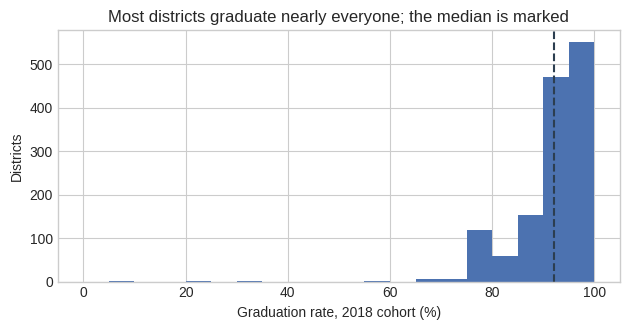

In [28]:
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.hist(sample["grad_rate_midpt"], bins=range(0, 105, 5), color="#4C72B0")
ax.axvline(sample["grad_rate_midpt"].median(), color="#2c3e50", ls="--", lw=1.5)
ax.set(xlabel="Graduation rate, 2018 cohort (%)", ylabel="Districts",
       title="Most districts graduate nearly everyone; the median is marked")
plt.tight_layout(); plt.show()

*Figure 1. Most districts graduate nearly everyone: the median district has a 92% graduation rate, and 74.7% are at or above 90%. The thin tail of low-graduation districts gives a skew of -3.18, because the rate cannot exceed 100.*

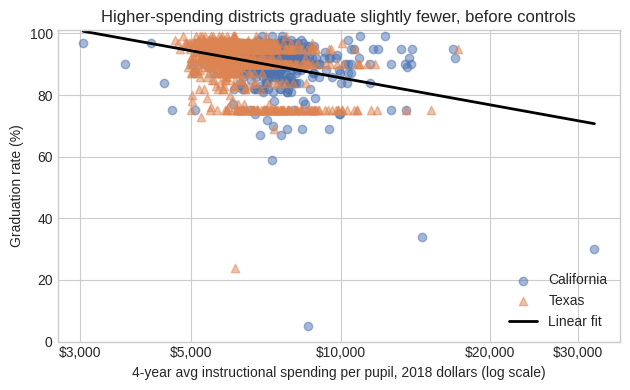

In [29]:
fig, ax = plt.subplots(figsize=(6.4, 4))
ca = sample["state_location"] == "CA"
ax.scatter(sample.loc[ca, "spending_4yr_avg"], sample.loc[ca, "grad_rate_midpt"], color="#4C72B0", alpha=0.5, label="California")
ax.scatter(sample.loc[~ca, "spending_4yr_avg"], sample.loc[~ca, "grad_rate_midpt"], color="#DD8452", marker="^", alpha=0.5, label="Texas")
slope, intercept = np.polyfit(sample["log_spending"], sample["grad_rate_midpt"], 1)
xs = np.linspace(sample["log_spending"].min(), sample["log_spending"].max(), 100)
ax.plot(np.exp(xs), intercept + slope * xs, color="black", lw=2, label="Linear fit")
ax.set_xscale("log")
ax.minorticks_off()
ax.set_xticks([3000, 5000, 10000, 20000, 30000])
ax.set_xticklabels(["$3,000", "$5,000", "$10,000", "$20,000", "$30,000"])
ax.set(xlabel="4-year avg instructional spending per pupil, 2018 dollars (log scale)", ylabel="Graduation rate (%)", ylim=(0, 101),
       title="Higher-spending districts graduate slightly fewer, before controls")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

*Figure 2. Before any controls, districts that spend more per pupil have slightly lower graduation rates, not higher (correlation -0.32; about 1.21 points lower for every 10% more spending). That is the opposite of what a spending-helps story predicts, which suggests the raw pattern reflects which kinds of districts spend more, such as state and size, rather than what spending does. The line is a raw fit with no controls. The vertical axis runs the full 0 to 100 and the horizontal axis is logarithmic, so equal distances are equal percentage changes in spending. The flat band at 75% is 105 districts (99 in Texas) reported at the midpoint of a range, not a real cluster.*

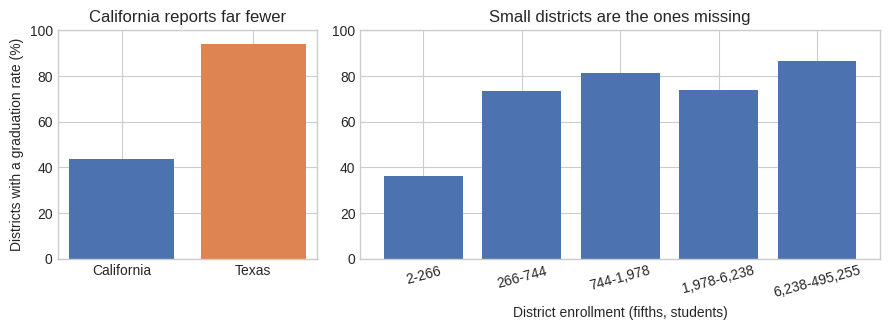

In [30]:
base = df.copy()                                    # all 2018 regular districts, with or without a graduation rate
base["has_rate"] = base["grad_rate_midpt"].notna()
base["size_group"] = pd.qcut(base["enrollment"], 5, duplicates="drop")
by_state = base.groupby("state_location")["has_rate"].mean() * 100
by_size = base.groupby("size_group", observed=True)["has_rate"].mean() * 100

fig, ax = plt.subplots(1, 2, figsize=(9, 3.4), gridspec_kw={"width_ratios": [1, 2]})
ax[0].bar(["California", "Texas"], [by_state["CA"], by_state["TX"]], color=["#4C72B0", "#DD8452"])
ax[0].set(ylabel="Districts with a graduation rate (%)", ylim=(0, 100), title="California reports far fewer")
ax[1].bar([f"{int(i.left):,}-{int(i.right):,}" for i in by_size.index], by_size.values, color="#4C72B0")
ax[1].set(xlabel="District enrollment (fifths, students)", ylim=(0, 100), title="Small districts are the ones missing")
ax[1].tick_params(axis="x", labelrotation=15)
plt.tight_layout(); plt.show()

*Figure 3. Graduation rates are far more often reported in Texas (94% of districts) than in California (44%), and for large districts than small ones: 36% of districts in the smallest enrollment fifth have one, against 87% in the largest. Of the 525 California districts without a rate, 437 have 'Elementary' in their name, which suggests they run no high school and so have no graduates to report. The sample therefore leans toward Texas and toward larger districts.*

In [31]:
table2 = sample.groupby("state_location").agg(districts=("leaid", "count"), grad_rate=("grad_rate_midpt", "mean"),
                                              spending=("spending_4yr_avg", "mean"), enrollment=("enrollment", "median"))
table2.index = ["California", "Texas"]
table2.columns = ["Districts", "Mean graduation rate (%)", "Mean 4-yr avg spending (2018 $)", "Median enrollment"]
table2.round(1)

,Districts,Mean graduation rate (%),Mean 4-yr avg spending (2018 $),Median enrollment
California,403,89.5,7723.0,4770.0
Texas,963,91.2,6441.7,1098.0


*Table 2. California districts in the sample spend more per pupil than Texas ones yet graduate slightly fewer students (89.5% against 91.2%), and district sizes differ widely (median enrollment 4,770 against 1,098). State differences alone could produce the negative raw association in Figure 2, which is why state enters the model as a control.*

## Section 3: The Model (25 pts)

Fit a multivariate OLS model and report it in a formatted regression table (coefficients, standard errors, N, R-squared), not a `summary()` dump. Interpret at least two coefficients in full: magnitude, units, direction, precision. For every control, say whether it blocks a confounding path or adds precision, and what would make it a bad control (Chapter 10). OLS only: no difference-in-differences estimate.

In [32]:
sample["texas"] = (sample["state_location"] == "TX").astype(int)
sample["log_enrollment"] = np.log(sample["enrollment"])
y = sample["grad_rate_midpt"]

specs = {"(1) Spending only": ["log_spending"],
         "(2) Adds state": ["log_spending", "texas"],
         "(3) Main: adds size": ["log_spending", "texas", "log_enrollment"]}
fits = {name: sm.OLS(y, sm.add_constant(sample[cols])).fit(cov_type="HC3", use_t=True) for name, cols in specs.items()}
m1, m2, m3 = fits.values()

def regtable(models, names):
    labels = {"log_spending": "Log 4-year avg spending per pupil", "texas": "Texas (California = 0)",
              "log_enrollment": "Log district enrollment", "const": "Constant"}
    index = [r for label in labels.values() for r in (label, label + " (se)")] + ["N", "R²"]
    rows = {}
    for name, m in zip(names, models):
        col = {}
        for v, label in labels.items():
            if v in m.params:
                col[label] = f"{m.params[v]:.2f}"
                col[label + " (se)"] = f"({m.bse[v]:.2f})"
        col["N"], col["R²"] = f"{int(m.nobs):,}", f"{m.rsquared:.2f}"
        rows[name] = col
    return pd.DataFrame(rows).reindex(index).fillna("")

regtable([m1, m2, m3], list(specs))

,(1) Spending only,(2) Adds state,(3) Main: adds size
Log 4-year avg spending per pupil,-12.69,-13.17,-9.48
Log 4-year avg spending per pupil (se),(1.95),(2.14),(2.36)
Texas (California = 0),,-0.49,1.28
Texas (California = 0) (se),,(0.50),(0.63)
Log district enrollment,,,0.94
Log district enrollment (se),,,(0.18)
Constant,202.45,207.04,166.19
Constant (se),(17.12),(18.92),(21.70)
N,"1,366","1,366","1,366"
R²,0.10,0.10,0.13


*Table 3. Regression of the 2018 cohort graduation rate (percentage points) on log 4-year average instructional spending per pupil (2018 dollars), for 1,366 California and Texas districts. Standard errors in parentheses are heteroskedasticity-robust (HC3), with t-based intervals. Column 3 is the main model. The constant is the predicted rate at a log spending of zero, far outside the data, so it is not interpreted.*

In [33]:
def spec_table(df, outcome, treatment, control_sets):
    rows = []
    for controls in control_sets:
        cols = [treatment] + list(controls)
        res = sm.OLS(df[outcome], sm.add_constant(df[cols]), missing="drop").fit(cov_type="HC3", use_t=True)
        rows.append({"controls": ", ".join(controls), "coef": res.params[treatment], "se": res.bse[treatment], "n": int(res.nobs)})
    return pd.DataFrame(rows, columns=["controls", "coef", "se", "n"])

spec = spec_table(sample, "grad_rate_midpt", "log_spending",
                  [[], ["texas"], ["log_enrollment"], ["texas", "log_enrollment"]])
print(spec.round(2).to_string(index=False))

# What leaving enrollment out costs is gamma x delta
gamma = m3.params["log_enrollment"]                                    # enrollment's effect on graduation, in the long model
delta = sm.OLS(sample["log_enrollment"], sm.add_constant(sample[["log_spending", "texas"]])).fit().params["log_spending"]
print(f"\ngamma (enrollment -> graduation)  = {gamma:.3f}")
print(f"delta (spending -> enrollment)    = {delta:.3f}")
print(f"gamma x delta                     = {gamma * delta:.2f}")
print(f"short minus long coefficient      = {m2.params['log_spending'] - m3.params['log_spending']:.2f}")

             controls   coef   se    n
                      -12.69 1.95 1366
                texas -13.17 2.14 1366
       log_enrollment -11.11 1.97 1366
texas, log_enrollment  -9.48 2.36 1366

gamma (enrollment -> graduation)  = 0.944
delta (spending -> enrollment)    = -3.905
gamma x delta                     = -3.69
short minus long coefficient      = -3.69


In [34]:
k = np.log(1.10)
b, (lo, hi) = m3.params["log_spending"], m3.conf_int().loc["log_spending"]
print(f"Main model: coefficient on log spending {b:.2f} (HC3 SE {m3.bse['log_spending']:.2f}, 95% CI {lo:.2f} to {hi:.2f}), "
      f"p = {m3.pvalues['log_spending']:.1e}")
print(f"10% more spending -> {b * k:+.2f} points (95% CI {lo * k:+.2f} to {hi * k:+.2f})")
med = sample["spending_4yr_avg"].median()
print(f"At the median spending of ${med:,.0f} per pupil (2018 dollars), 10% more is ${0.10 * med:,.0f}")
sd = sample["log_spending"].std()
print(f"One SD of log spending ({sd:.2f}, about {100 * (np.exp(sd) - 1):.0f}% more spending) -> {b * sd:+.2f} points, "
      f"{b * sd / sample['grad_rate_midpt'].std():+.2f} SD of the graduation rate")
print(f"Spending coefficient: {m1.params['log_spending']:.2f} with no controls, {m2.params['log_spending']:.2f} adding state, "
      f"{m3.params['log_spending']:.2f} adding size")

be, (elo, ehi) = m3.params["log_enrollment"], m3.conf_int().loc["log_enrollment"]
print(f"Enrollment: coefficient {be:.2f} (HC3 SE {m3.bse['log_enrollment']:.2f}), p = {m3.pvalues['log_enrollment']:.1e}; "
      f"a district twice as large -> {be * np.log(2):+.2f} points (95% CI {elo * np.log(2):+.2f} to {ehi * np.log(2):+.2f})")
bt, (tlo, thi) = m3.params["texas"], m3.conf_int().loc["texas"]
print(f"Texas vs California: {bt:+.2f} points (95% CI {tlo:+.2f} to {thi:+.2f}), p = {m3.pvalues['texas']:.3f}")
print(f"corr(log enrollment, log spending) = {sample['log_enrollment'].corr(sample['log_spending']):.2f};  "
      f"corr(log enrollment, graduation rate) = {sample['log_enrollment'].corr(sample['grad_rate_midpt']):.2f}")
print(f"N = {int(m3.nobs):,}, R² = {m3.rsquared:.3f} (spending only: {m1.rsquared:.3f})")

Main model: coefficient on log spending -9.48 (HC3 SE 2.36, 95% CI -14.12 to -4.85), p = 6.3e-05
10% more spending -> -0.90 points (95% CI -1.35 to -0.46)
At the median spending of $6,541 per pupil (2018 dollars), 10% more is $654
One SD of log spending (0.19, about 21% more spending) -> -1.81 points, -0.24 SD of the graduation rate
Spending coefficient: -12.69 with no controls, -13.17 adding state, -9.48 adding size
Enrollment: coefficient 0.94 (HC3 SE 0.18), p = 1.1e-07; a district twice as large -> +0.65 points (95% CI +0.41 to +0.89)
Texas vs California: +1.28 points (95% CI +0.04 to +2.53), p = 0.043
corr(log enrollment, log spending) = -0.25;  corr(log enrollment, graduation rate) = 0.23
N = 1,366, R² = 0.132 (spending only: 0.104)


**Roles of the controls.** *State* (Texas = 1) blocks a confounding path. California and Texas differ in how schools are funded, in graduation requirements and in how graduation rates are reported (Table 2 and Figure 3), all of which touch both spending and graduation. Adding it barely moves the spending coefficient (-12.69 to -13.17), so it matters little for the estimate and earns its place on design grounds. It would be a bad control only if spending decided which state a district is in, and it cannot, so it is neither a mediator nor a collider. *Log enrollment* also blocks a confounding path: size affects spending per pupil (the correlation is -0.25, because small districts spread fixed costs over fewer students) and affects graduation (the correlation is 0.23). It does most of the work here: adding it moves the spending coefficient from -13.17 to -9.48. That change of 3.69 is exactly the omitted-variable bias formula: enrollment's own effect on graduation (0.94) times how much enrollment changes with spending (-3.90 per unit of log spending, because high-spending districts are small) gives -3.69 (from the unrounded values), which is the gap between the short and the long regression. Leaving size out would have overstated the negative association. Enrollment would be a bad control if spending drew families into a district, because enrollment would then sit on the path from spending to graduation (a mediator) and holding it fixed would remove part of the effect I want; it would also be a bad control if enrollment responded to both spending and unmeasured school quality (a collider). Enrollment here is the 2018 count, measured after most of the spending, so I treat it as set mostly by the local population. Columns 2 and 3 show the estimate without and with it, and both are clearly negative. *Left out:* district poverty and student need. They are the obvious confounder, since higher-need districts tend to receive more funding and to graduate fewer students, which would produce a negative coefficient even if spending did nothing. The data here do not contain it, which is the main reason the -9.48 is not read as the effect of spending. There is no year control because the sample is one graduating cohort, so year does not vary.

## Section 4: Diagnostics (20 pts)

Residuals against fitted values and against your main predictor; a constant-variance check, with robust standard errors if it fails; variance inflation factors, interpreted; at least one influential-observation check.

**Start only after Topic 14.** Write Sections 1 to 3 first; they do not depend on it.

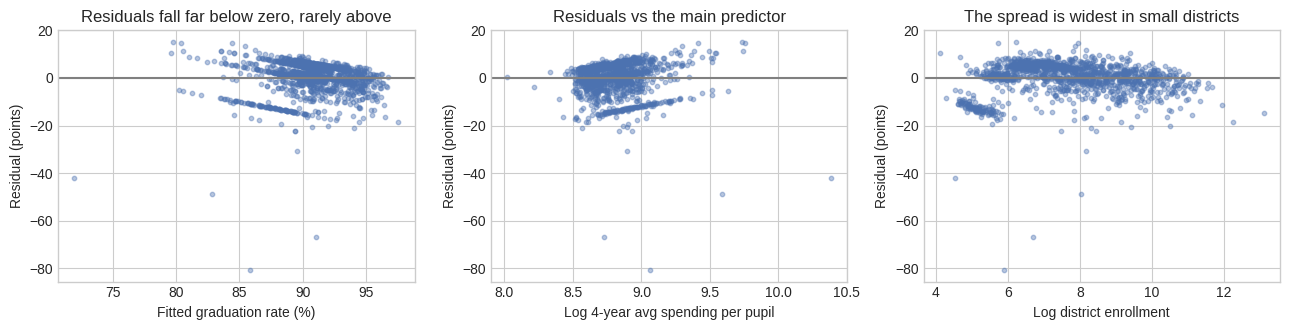

Breusch-Pagan (constant variance): LM = 32.0, p = 5.4e-07
Jarque-Bera (extreme values):      JB = 27,547, p = 0.0e+00; residual skew -2.86, kurtosis 24.2 (normal = 3)
Residual SD by enrollment fifth (points): [9.2, 5.6, 4.7, 6.2, 5.1]
The 105 districts reported at exactly 75%: mean residual -12.4 points, median enrollment 167
Largest residuals: -80.8 (lowest), 15.2 (highest)

term                 coef  classical SE   HC3 SE   ratio
const              166.19         11.56    21.70    1.88
log_spending        -9.48          1.23     2.36    1.93
texas                1.28          0.53     0.63    1.20
log_enrollment       0.94          0.14     0.18    1.23

VIF: {'log_spending': 1.52, 'texas': 1.63, 'log_enrollment': 1.44}


In [35]:
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import jarque_bera
from statsmodels.stats.outliers_influence import variance_inflation_factor

cols3 = ["log_spending", "texas", "log_enrollment"]
fit3 = sm.OLS(y, sm.add_constant(sample[cols3])).fit()
resid, fitted = fit3.resid, fit3.fittedvalues

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].scatter(fitted, resid, s=10, alpha=0.4, color="#4C72B0"); ax[0].axhline(0, color="grey")
ax[0].set(xlabel="Fitted graduation rate (%)", ylabel="Residual (points)", title="Residuals fall far below zero, rarely above")
ax[1].scatter(sample["log_spending"], resid, s=10, alpha=0.4, color="#4C72B0"); ax[1].axhline(0, color="grey")
ax[1].set(xlabel="Log 4-year avg spending per pupil", ylabel="Residual (points)", title="Residuals vs the main predictor")
ax[2].scatter(sample["log_enrollment"], resid, s=10, alpha=0.4, color="#4C72B0"); ax[2].axhline(0, color="grey")
ax[2].set(xlabel="Log district enrollment", ylabel="Residual (points)", title="The spread is widest in small districts")
plt.tight_layout(); plt.show()

# A formal test beside each picture
bp = het_breuschpagan(resid, fit3.model.exog)
jb = jarque_bera(resid)
print(f"Breusch-Pagan (constant variance): LM = {bp[0]:.1f}, p = {bp[1]:.1e}")
print(f"Jarque-Bera (extreme values):      JB = {jb[0]:,.0f}, p = {jb[1]:.1e}; residual skew {jb[2]:.2f}, kurtosis {jb[3]:.1f} (normal = 3)")
print("Residual SD by enrollment fifth (points):", resid.groupby(pd.qcut(sample["enrollment"], 5), observed=True).std().round(1).tolist())
at75 = sample["grad_rate_midpt"] == 75
print(f"The {at75.sum()} districts reported at exactly 75%: mean residual {resid[at75].mean():.1f} points, median enrollment {sample.loc[at75, 'enrollment'].median():.0f}")
print(f"Largest residuals: {resid.min():.1f} (lowest), {resid.max():.1f} (highest)")

# Classical and robust (HC3) standard errors side by side
rob3 = sm.OLS(y, sm.add_constant(sample[cols3])).fit(cov_type="HC3", use_t=True)        # = Section 3's column 3
print(f"\n{'term':<16}{'coef':>9}{'classical SE':>14}{'HC3 SE':>9}{'ratio':>8}")
for name in fit3.params.index:
    print(f"{name:<16}{fit3.params[name]:>9.2f}{fit3.bse[name]:>14.2f}{rob3.bse[name]:>9.2f}{rob3.bse[name] / fit3.bse[name]:>8.2f}")

# Variance inflation factors
Xv = sm.add_constant(sample[cols3]).values
print("\nVIF:", {name: round(float(variance_inflation_factor(Xv, i)), 2) for i, name in enumerate(["const"] + cols3) if name != "const"})

*Figure 4. The residuals are not evenly spread. They fall as low as 81 points below zero but never rise more than 15 above it, because a graduation rate cannot pass 100, and they are widest in the smallest districts. The band of points about 12 below zero is the 105 districts reported at the 75% range midpoint.*

**Residuals and extreme values.** The residuals sit around zero across the whole range of spending (middle panel) with no bend, so a straight line in log spending is not obviously wrong. Their shape is lopsided: with most districts near 95%, a straight line can miss far downward but hardly upward, which is the 100% ceiling at work. The Jarque-Bera test rejects normal-looking residuals by a wide margin (JB = 27,547, p < 0.001; skew -2.86 and kurtosis 24.2, against 3 for a normal distribution), which is that long lower tail. The band at -12 is a measurement feature, not a pattern in the districts: all 105 districts reported at exactly 75% have residuals between -5 and -20, 98% of them are among the smallest fifth of districts (median enrollment 167), and 75 is the midpoint of a reported range, not an observed rate.

**Constant variance.** The Breusch-Pagan test rejects constant variance (LM = 32.0, p < 0.001). The spread of the residuals is 9.2 points in the smallest fifth of districts against 4.7 to 6.2 elsewhere, which makes sense: a small district graduates a small class, so its rate swings more. The 75% districts are not the whole story, since leaving them out only brings the smallest-fifth spread down to 8.3. Unequal variance does not bias the coefficients, but it makes the usual standard errors wrong. For spending the classical standard error is 1.23 and the robust HC3 one is 2.36, 1.93 times as large; for the Texas indicator and for enrollment the ratios are smaller, 1.20 and 1.23. That is why every model in Table 3 reports HC3 standard errors: the classical ones would have made the spending coefficient look nearly twice as precise as it is.

**Collinearity.** The variance inflation factors are 1.52 for log spending, 1.63 for the Texas indicator and 1.44 for log enrollment, far below the usual warning level of 5. The predictors overlap somewhat (size and spending have a correlation of -0.25, and the two states differ in both), but not enough to make the coefficients unstable.

In [36]:
# Influence: which districts move the line most?
infl = fit3.get_influence()
leverage = pd.Series(infl.hat_matrix_diag, index=sample.index)
std_resid = pd.Series(infl.resid_studentized_internal, index=sample.index)
cooks = pd.Series(infl.cooks_distance[0], index=sample.index)
cut = 4 / len(sample)
print(f"Average leverage is {len(fit3.params) / len(sample):.4f}; {(std_resid.abs() > 3).sum()} districts have a standardised residual beyond 3")
print(f"Districts with Cook's distance above 4/N ({cut:.4f}): {(cooks > cut).sum()};  largest {cooks.max():.2f}")
top = cooks.nlargest(5).index
print(sample.loc[top, ["lea_name", "state_location", "enrollment", "spending_4yr_avg", "grad_rate_midpt"]]
      .assign(leverage=leverage[top].round(4), std_resid=std_resid[top].round(1), cooks_d=cooks[top].round(3)).to_string(index=False))
share = cooks[top].sum() / cooks.sum()
print(f"\n5 of {len(sample):,} districts ({5 / len(sample):.2%}) carry {share:.0%} of the total Cook's distance")

# Refit without rows, and a function for the HC3 standard error
def hc3_fit(data, features, term=None):
    """Fit graduation rate on `features` with a constant; HC3 errors, t-based intervals."""
    return sm.OLS(data["grad_rate_midpt"], sm.add_constant(data[features])).fit(cov_type="HC3", use_t=True)

def hc3_se(data, features, term):
    """Return the HC3 robust standard error of one coefficient."""
    return hc3_fit(data, features).bse[term]

without_top = hc3_fit(sample.drop(index=top[0]), cols3)
b_all, se_all = m3.params["log_spending"], m3.bse["log_spending"]
moved = abs(b_all - without_top.params["log_spending"])
print(f"\nWithout {sample.loc[top[0], 'lea_name']}: spending coefficient {b_all:.2f} -> {without_top.params['log_spending']:.2f}; "
      f"it moved {moved:.2f}, which is {moved / abs(b_all):.0%} of itself and {moved / se_all:.2f} of its standard error; "
      f"the HC3 standard error went from {se_all:.2f} to {without_top.bse['log_spending']:.2f}")

def spending_effect(label, d):
    m = hc3_fit(d, cols3)
    b, se = m.params["log_spending"], m.bse["log_spending"]
    print(f"{label:<46} coef {b:6.2f} (se {se:.2f}) -> {b * np.log(1.10):+.2f} points per 10% more spending, N = {int(m.nobs):,}")

county_agency = sample["lea_name"].str.contains("County Superintendent|Department of Education", case=False)
print()
spending_effect("Main model", sample)
spending_effect(f"Without {county_agency.sum()} county-level agencies", sample[~county_agency])
spending_effect("Without the 5 largest Cook's distances", sample.drop(index=top))
spending_effect(f"Without the {at75.sum()} districts reported at exactly 75%", sample[~at75])
spending_effect(f"Without all {(cooks > cut).sum()} districts above 4/N", sample[cooks <= cut])

Average leverage is 0.0029; 8 districts have a standardised residual beyond 3
Districts with Cook's distance above 4/N (0.0029): 73;  largest 0.55
                                 lea_name state_location  enrollment  spending_4yr_avg  grad_rate_midpt  leverage  std_resid  cooks_d
Tuolumne County Superintendent of Schools             CA        94.0      32352.718946             30.0    0.0551       -6.2    0.554
    Orange County Department of Education             CA      3093.0      14557.878205             34.0    0.0149       -7.0    0.187
                      Laytonville Unified             CA       360.0       8618.129557              5.0    0.0046      -11.6    0.155
                           BOYS RANCH ISD             TX       309.0      17210.377741             95.0    0.0275        2.1    0.032
                            FRANKSTON ISD             TX       804.0       6142.573122             24.0    0.0012       -9.6    0.029

5 of 1,366 districts (0.37%) carry 51% of the to

**Influence.** Leverage measures how unusual a district's predictor values are, the standardised residual measures how far its graduation rate sits from the line, and Cook's distance needs both. No district comes close to the usual cutoff of 1: the largest is 0.55. 73 districts are above the 4/N rule of thumb (0.0029), which is common in a sample of this size with a long lower tail, and 8 have a standardised residual beyond 3. Five districts (0.37% of the sample) carry 51% of the total Cook's distance. The top district shows why both parts matter. The Tuolumne County Superintendent of Schools (94 students, $32,353 per pupil, a 30% graduation rate) has a residual of -6.2 standard deviations, smaller than Laytonville Unified's -11.6, but a leverage of 0.055, about 19 times the average of 0.0029 (and 12 times Laytonville's 0.0046), because its spending is far above every other district's. So it ranks first and Laytonville third. Dropping it alone moves the spending coefficient from -9.48 to -7.79, which is 18% of itself and 0.72 of its standard error, and takes the HC3 standard error from 2.36 to 1.71, a fall of 28%. That is one district out of 1,366.

Two of the three most influential districts, Tuolumne and the Orange County Department of Education, are county-level agencies of the same special-purpose kind as the County Offices of Education I excluded in Section 1; they differ only in name, so the name filter missed them. The spending coefficient is -9.48 (0.90 points per 10% more spending) in the main model. It becomes -6.74 (0.64 points) without those two agencies, -7.23 (0.69) without the five largest Cook's distances, -10.18 (0.97) without all 73 districts above 4/N, and -6.53 (0.62, standard error 2.98) without the 105 districts reported at 75%. In every version the coefficient is negative and its 95% interval excludes zero, so the sign does not depend on any one group of districts, but the size varies from about 0.6 to 1.0 points per 10% more spending, and I treat the main estimate as one point in that range.

Deleting rows is the right call only for a reason that does not depend on the result, such as a record that is an error or lies outside the population being studied. It is data manipulation when rows go because they hurt the result, and a smaller standard error is never a reason to drop them. The two county agencies fit the first reason on their face, since they are the kind of agency Section 1 already excludes. But I found them through the influence check, not before, so I keep them in the main model and report the estimate without them beside it.

## Section 5: Threats and Conclusion (10 pts)

First the threats: what would have to be true for your main coefficient to be causal, is it, and if not, what your estimate is instead. Then the conclusion: what you found, how confident a reader should be, and what you would do with another month. Half a page. No new results, so there is no code cell here.

**Threats.** For the spending coefficient to be causal, districts that spend more would have to be otherwise the same as districts that spend less once state and size are held fixed. That is not true here, and the likeliest breaks run in opposite directions. First, need: districts with many low-income students often receive more money and graduate fewer students, and my data have no poverty measure, which can produce a negative coefficient with no effect of spending at all. Second, reverse causation: funding formulas can send more money to districts that are already struggling, so low graduation may lead to high spending and not the other way round. The measures are also stand-ins: spending is per pupil across every grade, not what a high school student received, and a national price index cannot adjust for the different price levels in California and Texas; 105 small districts also enter at a range midpoint (Section 4). I checked what I could, and the sign survives dropping any group of influential or midpoint districts, but those checks cannot supply a confounder I did not measure. So my estimate is a **conditional association**: among California and Texas districts that have a high school and report a rate, those that spend 10% more per pupil graduate about 0.9 percentage points fewer students than districts of the same state and size. It is not the effect of raising a district's spending.

**Conclusion.** Higher-spending districts graduate slightly fewer students: 0.90 points per 10% more spending (95% interval -1.35 to -0.46), and across the checks in Section 4 the figure stays between 0.6 and 1.0. A reader can be fairly confident of the sign and rough size of this association, and should have no confidence that spending lowers graduation: the model explains 13% of the variation across districts, and the most important confounder is missing. With another month I would add district poverty and student need from the same portal, add more graduating cohorts so that each district can be compared with itself, and, if a funding reform changed some districts' budgets and not others, estimate its effect with a difference-in-differences. That design would buy a before-and-after comparison, and it would assume that the two groups of districts were on parallel paths until the reform.

## Appendix

The regression table, the diagnostics output and any extra figures. The appendix does not count toward the 6–8 page limit of the report.

## Numbers my report quotes

Every number in your report, each with a name that says where it comes from. A number in the report that this cell does not print is unsupported, and is graded as if it were missing. Keep it the last code cell.

In [37]:
# ---- values the report quotes, computed here so every number below is printed by a cell ----
grad = sample["grad_rate_midpt"]
no_rate = base[~base["has_rate"]]
no_rate_ca = no_rate[no_rate["state_location"] == "CA"]
k10 = np.log(1.10)
pf = lambda p: "< 0.001" if p < 0.001 else f"{p:.3f}"
lay = sample["lea_name"].eq("Laytonville Unified").idxmax()
t = top[0]
avg_lev = len(fit3.params) / len(sample)

# County Offices of Education that the Section 1 rule drops and that would otherwise be in the sample
g0 = pd.read_csv(GRAD_FILE, encoding="utf-8-sig")
g0 = g0[(g0["agency_type"] == target_agency) & (g0["year"] == COHORT_YEAR)].copy()
g0["rate"] = pd.to_numeric(g0["grad_rate_midpt"], errors="coerce")
g0["enr"] = pd.to_numeric(g0["enrollment"], errors="coerce").replace(0, np.nan)
f0 = pd.concat([pd.read_csv(FIN_FILE_EARLY, encoding="utf-8-sig"), pd.read_csv(FIN_FILE_2018, encoding="utf-8-sig")])
f0 = f0[f0["year"].isin(SPEND_YEARS) & (f0["agency_type"] == target_agency)].drop_duplicates(["leaid", "year"])
f0["spp"] = pd.to_numeric(f0["exp_current_instruction_total"], errors="coerce") / pd.to_numeric(f0["enrollment"], errors="coerce").replace(0, np.nan)
full4 = f0.pivot(index="leaid", columns="year", values="spp").reindex(columns=SPEND_YEARS).notna().all(axis=1)
coe_ids = set(g0.loc[g0["lea_name"].str.contains("County Office of Education", case=False), "leaid"]) | \
          set(f0.loc[f0["lea_name"].str.contains("County Office of Education", case=False), "leaid"])    # the rule matches the name in either file
coe_rows = f0[f0["lea_name"].str.contains("County Office of Education", case=False)]      # all County Office district-years, 2015-2018
n_coe = int((g0["leaid"].isin(coe_ids) & g0["rate"].notna() & g0["enr"].notna() & g0["leaid"].isin(full4[full4].index)).sum())

# Section 4 helper values
rs_fifth = resid.groupby(pd.qcut(sample["enrollment"], 5), observed=True).std()
rs_fifth_no75 = resid[~at75].groupby(pd.qcut(sample["enrollment"], 5)[~at75], observed=True).std()
vifs = {name: float(variance_inflation_factor(Xv, i)) for i, name in enumerate(["const"] + cols3) if name != "const"}
alt = {"two county agencies": hc3_fit(sample[~county_agency], cols3), "five largest Cook's": hc3_fit(sample.drop(index=top), cols3),
       "all above 4/N": hc3_fit(sample[cooks <= cut], cols3), "districts at 75%": hc3_fit(sample[~at75], cols3)}
b3, se3 = m3.params["log_spending"], m3.bse["log_spending"]
lo3, hi3 = m3.conf_int().loc["log_spending"]
be, ee = m3.params["log_enrollment"], m3.bse["log_enrollment"]
elo, ehi = m3.conf_int().loc["log_enrollment"]
tx_lo, tx_hi = m3.conf_int().loc["texas"]
sd_ls = sample["log_spending"].std()

REPORT_NUMBERS = {
    # Section 1: prices, sample flow, missingness, Table 1
    "Section 1: CPI-U annual average 2015": float(cpi_year[2015]),
    "Section 1: CPI-U annual average 2018": float(cpi_year[2018]),
    "Section 1: prices rose 2015 to 2018 (%)": round(100 * (cpi_year[2018] / cpi_year[2015] - 1), 1),
    "Section 1: one 2015 dollar in 2018 dollars": round(cpi_year[2018] / cpi_year[2015], 3),
    "Section 1: regular districts in 2018 (no County Offices)": n_regular,
    "Section 1: districts with a graduation rate": n_with_grad,
    "Section 1: also with complete 4-year spending (estimation sample)": n_with_spend,
    "Section 1: districts without a graduation rate": n_regular - n_with_grad,
    "Section 1: ... of which in California": len(no_rate_ca),
    "Section 1: ... of which 'Elementary' in the name (California)": int(no_rate_ca["lea_name"].str.contains("Elementary", case=False).sum()),
    "Section 1: County Offices of Education dropped that would be in the sample": n_coe,
    "Section 1: County Office district-years above $100,000 per pupil": int((coe_rows["spp"] > 100000).sum()),
    "Section 1: ... County Offices involved": int(coe_rows.loc[coe_rows["spp"] > 100000, "leaid"].nunique()),
    "Section 1: share with a rate, smallest enrollment fifth (%)": round(by_size.iloc[0]),
    "Section 1: share with a rate, 2nd fifth (%)": round(by_size.iloc[1]),
    "Section 1: share with a rate, 3rd fifth (%)": round(by_size.iloc[2]),
    "Section 1: share with a rate, 4th fifth (%)": round(by_size.iloc[3]),
    "Section 1: share with a rate, largest enrollment fifth (%)": round(by_size.iloc[4]),
    "Section 1: share of districts with a rate, Texas (%)": round(by_state["TX"]),
    "Section 1: share of districts with a rate, California (%)": round(by_state["CA"]),
    "Section 1: districts reported at exactly 75%": int((grad == 75).sum()),
    "Section 1: ... of which in Texas": int(((grad == 75) & (sample["state_location"] == "TX")).sum()),
    "Section 1: graduation rate mean (%)": round(grad.mean(), 1),
    "Section 1: graduation rate std dev": round(grad.std(), 1),
    "Section 1: graduation rate median (%)": round(grad.median(), 1),
    "Section 1: graduation rate minimum (%)": round(grad.min(), 1),
    "Section 1: 4-year avg spending in 2018 dollars, median ($)": round(sample["spending_4yr_avg"].median()),
    "Section 1: 4-year avg spending in 2018 dollars, mean ($)": round(sample["spending_4yr_avg"].mean()),
    "Section 1: same average before price adjustment, median ($)": round(sample["spending_4yr_nominal"].median()),
    "Section 1: same average before price adjustment, mean ($)": round(sample["spending_4yr_nominal"].mean()),
    "Section 1: price adjustment raises the mean by ($)": round(sample["spending_4yr_avg"].mean() - sample["spending_4yr_nominal"].mean()),
    "Section 1: 2018 spending per pupil, mean ($)": round(sample["spending_per_pupil"].mean()),
    "Section 1: enrollment median": round(sample["enrollment"].median()),
    "Section 1: enrollment mean": round(sample["enrollment"].mean()),
    "Section 1: enrollment maximum": round(sample["enrollment"].max()),
    # Section 2: Figures 1-3 and Table 2
    "Section 2: share of districts at or above 90% (%)": round((grad >= 90).mean() * 100, 1),
    "Section 2: skew of graduation rate": round(grad.skew(), 2),
    "Section 2: skew of spending (dollars)": round(sample["spending_4yr_avg"].skew(), 2),
    "Section 2: skew of spending (log)": round(sample["log_spending"].skew(), 2),
    "Section 2: correlation, log spending and graduation rate": round(sample["log_spending"].corr(grad), 2),
    "Section 2: raw points per 10% more spending": round(slope * k10, 2),
    "Section 2: mean spending, California ($)": round(table2.loc["California", "Mean 4-yr avg spending (2018 $)"]),
    "Section 2: mean spending, Texas ($)": round(table2.loc["Texas", "Mean 4-yr avg spending (2018 $)"]),
    "Section 2: mean graduation rate, California (%)": round(table2.loc["California", "Mean graduation rate (%)"], 1),
    "Section 2: mean graduation rate, Texas (%)": round(table2.loc["Texas", "Mean graduation rate (%)"], 1),
    "Section 2: median enrollment, California": round(table2.loc["California", "Median enrollment"]),
    "Section 2: median enrollment, Texas": round(table2.loc["Texas", "Median enrollment"]),
    # Section 3: Table 3, the spec table, gamma x delta, the two interpreted coefficients
    "Section 3: spending coefficient, column 1": round(m1.params["log_spending"], 2),
    "Section 3: spending coefficient, column 1 (se)": round(m1.bse["log_spending"], 2),
    "Section 3: spending coefficient, column 2": round(m2.params["log_spending"], 2),
    "Section 3: spending coefficient, column 2 (se)": round(m2.bse["log_spending"], 2),
    "Section 3: spending coefficient, column 3 (main)": round(b3, 2),
    "Section 3: spending coefficient, column 3 (se)": round(se3, 2),
    "Section 3: spending coefficient, 95% CI low": round(lo3, 2),
    "Section 3: spending coefficient, 95% CI high": round(hi3, 2),
    "Section 3: spending coefficient, p-value": pf(m3.pvalues["log_spending"]),
    "Section 3: spending coefficient with enrollment only": round(spec.loc[2, "coef"], 2),
    "Section 3: Texas coefficient, column 2": round(m2.params["texas"], 2),
    "Section 3: Texas coefficient, column 2 (se)": round(m2.bse["texas"], 2),
    "Section 3: Texas coefficient, column 3": round(m3.params["texas"], 2),
    "Section 3: Texas coefficient, column 3 (se)": round(m3.bse["texas"], 2),
    "Section 3: Texas coefficient, 95% CI low": round(tx_lo, 2),
    "Section 3: Texas coefficient, 95% CI high": round(tx_hi, 2),
    "Section 3: Texas coefficient, p-value": pf(m3.pvalues["texas"]),
    "Section 3: enrollment coefficient": round(be, 2),
    "Section 3: enrollment coefficient (se)": round(ee, 2),
    "Section 3: enrollment coefficient, p-value": pf(m3.pvalues["log_enrollment"]),
    "Section 3: constant, column 1": round(m1.params["const"], 2),
    "Section 3: constant, column 2": round(m2.params["const"], 2),
    "Section 3: constant, column 3": round(m3.params["const"], 2),
    "Section 3: N": int(m3.nobs),
    "Section 3: R2, column 1": round(m1.rsquared, 2),
    "Section 3: R2, column 2": round(m2.rsquared, 2),
    "Section 3: R2, column 3 (main)": round(m3.rsquared, 2),
    "Section 3: median spending, 2018 $ per pupil": round(sample["spending_4yr_avg"].median()),
    "Section 3: 10% of median spending ($)": round(0.10 * sample["spending_4yr_avg"].median()),
    "Section 3: points per 10% more spending": round(b3 * k10, 2),
    "Section 3: points per 10% more spending, CI low": round(lo3 * k10, 2),
    "Section 3: points per 10% more spending, CI high": round(hi3 * k10, 2),
    "Section 3: one SD of log spending": round(sd_ls, 2),
    "Section 3: one SD of log spending, % more spending": round(100 * (np.exp(sd_ls) - 1)),
    "Section 3: one SD of log spending, points": round(b3 * sd_ls, 2),
    "Section 3: one SD of log spending, SD of graduation rate": round(b3 * sd_ls / grad.std(), 2),
    "Section 3: points for a district twice as large": round(be * np.log(2), 2),
    "Section 3: points for twice as large, CI low": round(elo * np.log(2), 2),
    "Section 3: points for twice as large, CI high": round(ehi * np.log(2), 2),
    "Section 3: corr(log enrollment, log spending)": round(sample["log_enrollment"].corr(sample["log_spending"]), 2),
    "Section 3: corr(log enrollment, graduation rate)": round(sample["log_enrollment"].corr(grad), 2),
    "Section 3: gamma (enrollment -> graduation)": round(gamma, 2),
    "Section 3: delta (spending -> enrollment)": round(delta, 2),
    "Section 3: gamma x delta": round(gamma * delta, 2),
    "Section 3: short minus long spending coefficient": round(m2.params["log_spending"] - m3.params["log_spending"], 2),
    # Section 4: diagnostics
    "Section 4: Breusch-Pagan LM": round(bp[0], 1),
    "Section 4: Breusch-Pagan p-value": pf(bp[1]),
    "Section 4: Jarque-Bera statistic": round(jb[0]),
    "Section 4: Jarque-Bera p-value": pf(jb[1]),
    "Section 4: residual skew": round(jb[2], 2),
    "Section 4: residual kurtosis": round(jb[3], 1),
    "Section 4: lowest residual (points)": round(resid.min(), 1),
    "Section 4: highest residual (points)": round(resid.max(), 1),
    "Section 4: residual SD, smallest enrollment fifth": round(rs_fifth.iloc[0], 1),
    "Section 4: residual SD, other four fifths, lowest": round(rs_fifth.iloc[1:].min(), 1),
    "Section 4: residual SD, other four fifths, highest": round(rs_fifth.iloc[1:].max(), 1),
    "Section 4: residual SD, smallest fifth without the 75% districts": round(rs_fifth_no75.iloc[0], 1),
    "Section 4: classical SE, spending": round(fit3.bse["log_spending"], 2),
    "Section 4: HC3 SE, spending": round(rob3.bse["log_spending"], 2),
    "Section 4: HC3 / classical SE, spending": round(rob3.bse["log_spending"] / fit3.bse["log_spending"], 2),
    "Section 4: HC3 / classical SE, Texas": round(rob3.bse["texas"] / fit3.bse["texas"], 2),
    "Section 4: HC3 / classical SE, enrollment": round(rob3.bse["log_enrollment"] / fit3.bse["log_enrollment"], 2),
    "Section 4: VIF, log spending": round(vifs["log_spending"], 2),
    "Section 4: VIF, Texas": round(vifs["texas"], 2),
    "Section 4: VIF, log enrollment": round(vifs["log_enrollment"], 2),
    "Section 4: mean residual, districts at 75% (points)": round(resid[at75].mean(), 1),
    "Section 4: share of 75% districts with residual between -20 and -5 (%)": round(100 * ((resid[at75] < -5) & (resid[at75] > -20)).mean()),
    "Section 4: share of 75% districts in the smallest fifth (%)": round(100 * (pd.qcut(sample["enrollment"], 5, labels=False)[at75] == 0).mean()),
    "Section 4: median enrollment of the 75% districts": round(sample.loc[at75, "enrollment"].median()),
    "Section 4: largest Cook's distance": round(cooks.max(), 2),
    "Section 4: Cook's distance cutoff 4/N": round(cut, 4),
    "Section 4: districts above 4/N": int((cooks > cut).sum()),
    "Section 4: districts with standardised residual beyond 3": int((std_resid.abs() > 3).sum()),
    "Section 4: average leverage": round(avg_lev, 4),
    "Section 4: five largest Cook's share of the total (%)": round(100 * share),
    "Section 4: five districts as a share of the sample (%)": round(100 * 5 / len(sample), 2),
    "Section 4: most influential district": sample.loc[t, "lea_name"],
    "Section 4: its enrollment": int(sample.loc[t, "enrollment"]),
    "Section 4: its spending (2018 $ per pupil)": round(sample.loc[t, "spending_4yr_avg"]),
    "Section 4: its graduation rate (%)": round(sample.loc[t, "grad_rate_midpt"]),
    "Section 4: its standardised residual": round(std_resid[t], 1),
    "Section 4: its leverage": round(leverage[t], 3),
    "Section 4: its leverage / average leverage": round(leverage[t] / avg_lev),
    "Section 4: Laytonville standardised residual": round(std_resid[lay], 1),
    "Section 4: Laytonville leverage": round(leverage[lay], 4),
    "Section 4: its leverage / Laytonville leverage": round(leverage[t] / leverage[lay]),
    "Section 4: coefficient without the top district": round(without_top.params["log_spending"], 2),
    "Section 4: ... moved, % of itself": round(100 * moved / abs(b3)),
    "Section 4: ... moved, in standard errors": round(moved / se3, 2),
    "Section 4: ... HC3 standard error without it": round(without_top.bse["log_spending"], 2),
    "Section 4: ... standard error change (%)": round(100 * (without_top.bse["log_spending"] / se3 - 1)),
    "Section 4: county-level agencies dropped": int(county_agency.sum()),
    "Section 4: coefficient without them": round(alt["two county agencies"].params["log_spending"], 2),
    "Section 4: ... per 10% more spending": round(alt["two county agencies"].params["log_spending"] * k10, 2),
    "Section 4: ... standard error": round(alt["two county agencies"].bse["log_spending"], 2),
    "Section 4: ... N": int(alt["two county agencies"].nobs),
    "Section 4: coefficient without the five largest Cook's distances": round(alt["five largest Cook's"].params["log_spending"], 2),
    "Section 4: ... per 10% more spending (five largest)": round(alt["five largest Cook's"].params["log_spending"] * k10, 2),
    "Section 4: coefficient without all districts above 4/N": round(alt["all above 4/N"].params["log_spending"], 2),
    "Section 4: ... per 10% more spending (all above 4/N)": round(alt["all above 4/N"].params["log_spending"] * k10, 2),
    "Section 4: coefficient without the 75% districts": round(alt["districts at 75%"].params["log_spending"], 2),
    "Section 4: ... per 10% more spending (75% districts)": round(alt["districts at 75%"].params["log_spending"] * k10, 2),
    "Section 4: ... standard error (75% districts)": round(alt["districts at 75%"].bse["log_spending"], 2),
}

for name, value in REPORT_NUMBERS.items():
    print(f"{name}: {value}")

Section 1: CPI-U annual average 2015: 237.017
Section 1: CPI-U annual average 2018: 251.107
Section 1: prices rose 2015 to 2018 (%): 5.9
Section 1: one 2015 dollar in 2018 dollars: 1.059
Section 1: regular districts in 2018 (no County Offices): 1958
Section 1: districts with a graduation rate: 1371
Section 1: also with complete 4-year spending (estimation sample): 1366
Section 1: districts without a graduation rate: 587
Section 1: ... of which in California: 525
Section 1: ... of which 'Elementary' in the name (California): 437
Section 1: County Offices of Education dropped that would be in the sample: 40
Section 1: County Office district-years above $100,000 per pupil: 17
Section 1: ... County Offices involved: 7
Section 1: share with a rate, smallest enrollment fifth (%): 36
Section 1: share with a rate, 2nd fifth (%): 73
Section 1: share with a rate, 3rd fifth (%): 81
Section 1: share with a rate, 4th fifth (%): 74
Section 1: share with a rate, largest enrollment fifth (%): 87
Secti

## Checkpoints

In Colab, *File › Save a copy in GitHub* makes a commit each time you use it. Save at each checkpoint so the commit history shows it.

- [ ] **Mon 26 Oct:** your question and data source, posted in the Midterm checkpoint 1 discussion.
- [ ] **Mon 2 Nov:** your data loaded and your summary table, committed to your repository.
- [ ] **Fri 6 Nov:** a draft of your model, committed.
- [ ] **Mon 9 Nov, 11:59pm:** the project is due.

## Before you submit

- [ ] A Colab notebook with all your analysis, cleanly organised.
- [ ] A written report, 6 to 8 pages of text, uploaded as a PDF.
- [ ] A GitHub repository containing both, with a `README.md` you wrote yourself.
- [ ] **Question and data provenance (20):** A defensible measurable question; data described as a measurement product; missingness mechanism identified and defended; interpretable summary table
- [ ] **Descriptive evidence (20):** Two or more figures each making a stated point; captions state findings not variables; Chapter 3 standards met
- [ ] **Model and interpretation (25):** Properly formatted regression table; two coefficients interpreted in full including units and magnitude; every control justified by role
- [ ] **Diagnostics (20):** Residuals, heteroskedasticity, VIF and influence all run and interpreted; robust errors used where warranted
- [ ] **Threats and conclusion (10):** The causal claim assessed in plain terms; the estimand correctly labelled if not causal; conclusion adds no new results
- [ ] **Repository, checkpoints and reproducibility (5):** Public GitHub repo containing the notebook and the report; the two committed checkpoints visible in the commit history; data included or its download documented; a self-written README giving the question, the source, how to run it and the headline finding
- [ ] The Colab notebook is shared with *Anyone with the link*, and the link is in the Canvas submission box.
- [ ] Every number in the report is printed by the *Numbers my report quotes* cell.
- [ ] No AI anywhere: code, analysis, writing, editing, README.
- [ ] *File › Save a copy in GitHub*, path `Midterm Project/Econ_3916_Midterm.ipynb`.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.